# 08 — Scenarios and risk: prices, output, costs and timing drawn together

A book of leases and power requests fails together when oil collapses, gas spikes, the wind is weak and a plant arrives late. This notebook draws 2,000 reproducible joint scenarios for the forty candidates of notebook 07 — block-bootstrapped monthly joint shocks of WTI, Henry Hub and the ERCOT price (the correlations and the 2020 and 2022 episodes travel together) on prices that revert toward their 2018–2024 real means, output multipliers from the scored forecast residuals of notebook 05, cost multipliers from the grid, and operation years for the power requests from the queue models' curves through the copula of the book simulation — values each candidate under every scenario, measures its risk (P(NPV < 0), VaR, CVaR) alone and in the book, runs the named stresses, builds a second scenario set from a Gaussian copula that notebook 09 keeps out of sample, and removes the correlations to measure what they are worth. Where a candidate's data are thin (completeness below 1), its output uncertainty is widened by the inverse of its completeness (PLAN.md §14 addendum).

**Inputs → Outputs**

| | Path | Notes |
|---|---|---|
| in | `results/candidate_npv.csv`, `results/upstream_cost_grid.csv`, `results/candidate_capture_factors.csv` | notebook 07 part B |
| in | `data/interim/market_monthly.parquet`, `data/interim/upstream_monthly.parquet` | notebook 01 |
| in | `data/processed/forecasts_holdout.parquet` | notebook 05 (scored residuals) |
| in | `data/processed/predictions_landmark.parquet`, `data/processed/predictions_v2.parquet`, `results/book_rho.csv`, `results/atb_costs.csv`, `results/cost_table.csv` | notebooks 04 and 07 part A; ρ from notebook 09 part A's book simulation (a committed registered result) |
| out | `data/interim/scenario_prices_primary.npy`, `data/interim/scenario_prices_copula.npy` | price paths (scenarios × months × series), rebuilt by seed |
| out | `data/processed/candidate_npv_scenarios.parquet` | NPV of every candidate in every scenario: primary, held-out copula and independent (ablation) sets, merchant and contracted |
| out | `results/stress_candidates.csv` | NPV of every candidate under each named stress (for the stability test of notebook 09) |
| out | `results/scenario_settings.csv`, `results/scenario_price_bands.csv`, `results/scenario_correlation.csv` | the registered settings, the fan bands, the correlation check |
| out | `results/scenario_summary.csv`, `results/stress_tests.csv`, `results/correlation_ablation.csv`, `results/scenarios_checks.csv` | risk per candidate and per book; stresses; the ablation; checks |
| out | `figures/F30_price_scenarios.*`, `figures/F31_candidate_risk.*`, `figures/F32_stresses.*` | the pictures |

*Execution order:* runs after notebook 07.

## Setup

In [1]:
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append(str(Path.cwd().resolve().parent))  # notebooks run from notebooks/; src/ is one level up
from src import config, economics as ec, paths, plots, portfolio, scenarios as sc, value

paths.ensure_dirs()
plots.set_style()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
warnings.filterwarnings("ignore", category=FutureWarning)

NOTEBOOK = "08_scenarios_and_risk"
START = time.time()
R = paths.RESULTS
N_SCEN, HORIZON, BLOCK, SEED, LEVEL = 2000, 240, 12, 2020, 0.95  # registered settings (decision #69)
LIFE, HORIZON_YEARS = 20, 7
POWER_TECHS = {"Gas": "Gas CC", "Solar": "Solar", "Wind": "Wind", "Battery": "Storage"}
PPA = {"Solar": 57.0, "Wind": 62.0}


def save(fig, name, caption):
    """Save a figure of this notebook under figures/08_scenarios_and_risk/ with its caption stub."""
    return plots.save_fig(fig, name, caption, NOTEBOOK, folder=NOTEBOOK)


def pct(x, digits=1):
    return f"{100 * x:.{digits}f}%"


book = pd.read_csv(R / "candidate_npv.csv")
grid = pd.read_csv(R / "upstream_cost_grid.csv").set_index("item")
capture = pd.read_csv(R / "candidate_capture_factors.csv").set_index("technology")
market = pd.read_parquet(paths.DATA_INTERIM / "market_monthly.parquet")
lease = pd.read_parquet(paths.DATA_INTERIM / "upstream_monthly.parquet")
forecasts = pd.read_parquet(paths.DATA_PROCESSED / "forecasts_holdout.parquet")
pred_landmark = pd.read_parquet(paths.DATA_PROCESSED / "predictions_landmark.parquet")
pred_v2 = pd.read_parquet(paths.DATA_PROCESSED / "predictions_v2.parquet")
atb = pd.read_csv(R / "atb_costs.csv").set_index("tech")
rho_table = pd.read_csv(R / "book_rho.csv")
rho = float(rho_table.loc[rho_table.iloc[:, 0].astype(str).str.lower().str.contains("all|pooled|book"), "rho"].iloc[0]) if "rho" in rho_table.columns and rho_table.iloc[:, 0].astype(str).str.lower().str.contains("all|pooled|book").any() else float(rho_table["rho"].iloc[0]) if "rho" in rho_table.columns else 0.041
dam = pd.read_parquet(paths.RAW_ERCOT / "ercot_dam_spp_2024.parquet")
hub = dam[dam["Location"] == config.ERCOT_PRICE_HUB].set_index("Interval Start")["SPP"]
wind_solar = pd.read_parquet(paths.RAW_ERCOT / "ercot_wind_solar_2024.parquet")
m24 = market[market["month"].dt.year == 2024]
BASE = np.array([m24["wti_usd_bbl_real2024"].mean(), m24["hh_usd_mmbtu_real2024"].mean(), m24["ercot_usd_mwh_real2024"].mean()])
window = market[market["month"].between("2018-01-01", "2024-12-01")]
LONG_RUN = np.array([window["wti_usd_bbl_real2024"].mean(), window["hh_usd_mmbtu_real2024"].mean(), window["ercot_usd_mwh_real2024"].mean()])  # OBSERVED 2018–2024 real means
HALF_LIFE = sc.HALF_LIFE_MONTHS  # ASSUMED four-year half-life of the reversion
leases = book[book["sector"] != "ERCOT power"].reset_index(drop=True)
power = book[book["sector"] == "ERCOT power"].reset_index(drop=True)
settings = pd.DataFrame([{"n_scenarios": N_SCEN, "horizon_months": HORIZON, "block_months": BLOCK, "seed_primary": SEED, "seed_copula": SEED + 1, "level": LEVEL,
                          "rho_book": rho, "base_wti": BASE[0], "base_hh": BASE[1], "base_ercot": BASE[2], "long_run_wti": LONG_RUN[0], "long_run_hh": LONG_RUN[1], "long_run_ercot": LONG_RUN[2],
                          "half_life_months": HALF_LIFE, "history": "2018-01 to 2024-12 monthly log changes (ERCOT 2020–2023 ASSUMED); shocks demeaned; mean reversion to the 2018–2024 real means"}])
settings.to_csv(R / "scenario_settings.csv", index=False)
print(f"{len(leases)} leases and {len(power)} requests; 2024 base WTI ${BASE[0]:.1f}, Henry Hub ${BASE[1]:.2f}, ERCOT ${BASE[2]:.1f}; "
      f"long-run (2018–2024 real means) ${LONG_RUN[0]:.1f}, ${LONG_RUN[1]:.2f}, ${LONG_RUN[2]:.1f}; half-life {HALF_LIFE} months; ρ = {rho:.3f}")


20 leases and 20 requests; 2024 base WTI $76.6, Henry Hub $2.19, ERCOT $27.0; long-run (2018–2024 real means) $76.5, $3.68, $39.7; half-life 48 months; ρ = 0.041


## 1. Joint price paths: bootstrapped shocks around a mean-reverting level, and the held-out copula

Monthly log changes of the three prices over 2018–2024 (83 months, the ERCOT part of 2020–2023 assumed) are resampled in blocks of twelve months, the same months for every series, demeaned, and applied as shocks to a log price that reverts toward the 2018–2024 real mean with a four-year half-life (ASSUMED; a twenty-year random walk of these changes would put WTI anywhere from $13 to $800 a barrel ten years out, which is not a planning case). The jumps and the cross-correlations are the history's; the drift and the unbounded variance are not. A Gaussian copula on the same marginals makes a second shock set that notebook 09 keeps out of sample. The check: the simulated cross-correlations of the shocks against the historical ones.

In [2]:
changes = sc.joint_log_changes(market)
primary = sc.block_bootstrap_paths(changes, N_SCEN, HORIZON, block=BLOCK, seed=SEED)
copula = sc.gaussian_copula_paths(changes, N_SCEN, HORIZON, seed=SEED + 1)
prices_primary = sc.mean_reverting_prices(primary, BASE, LONG_RUN, HALF_LIFE)
prices_copula = sc.mean_reverting_prices(copula, BASE, LONG_RUN, HALF_LIFE)
np.save(paths.DATA_INTERIM / "scenario_prices_primary.npy", prices_primary)
np.save(paths.DATA_INTERIM / "scenario_prices_copula.npy", prices_copula)
names = ["WTI", "Henry Hub", "ERCOT"]
hist_corr = np.corrcoef(changes.T)
corr_rows = []
for label, paths_ in (("primary (block bootstrap)", primary), ("held-out (Gaussian copula)", copula)):
    c = np.corrcoef(paths_.reshape(-1, 3).T)
    for i in range(3):
        for j in range(i + 1, 3):
            corr_rows.append({"generator": label, "pair": f"{names[i]}–{names[j]}", "historical": hist_corr[i, j], "simulated": c[i, j]})
corr_table = pd.DataFrame(corr_rows)
corr_table.to_csv(R / "scenario_correlation.csv", index=False)
years = np.arange(HORIZON) // 12 + 2025
bands = []
for k, name in enumerate(names):
    for y in range(2025, 2025 + HORIZON // 12):
        sel = prices_primary[:, years == y, k].mean(axis=1)
        bands.append({"series": name, "year": y, **{f"q{int(q * 100):02d}": float(np.quantile(sel, q)) for q in (0.05, 0.25, 0.5, 0.75, 0.95)}})
bands = pd.DataFrame(bands)
bands.to_csv(R / "scenario_price_bands.csv", index=False)
print(f"{N_SCEN} paths × {HORIZON} months; history {len(changes)} months; correlations historical vs primary: "
      + "; ".join(f"{r['pair']} {r['historical']:.2f}→{r['simulated']:.2f}" for _, r in corr_table[corr_table['generator'].str.startswith('primary')].iterrows())
      + f"; {time.time() - START:.0f} s")
corr_table.round(3)


2000 paths × 240 months; history 83 months; correlations historical vs primary: WTI–Henry Hub 0.06→0.07; WTI–ERCOT 0.05→0.05; Henry Hub–ERCOT 0.38→0.41; 1 s


,generator,pair,historical,simulated
0,primary (block bootstrap),WTI–Henry Hub,0.060,0.072
1,primary (block bootstrap),WTI–ERCOT,0.047,0.052
2,primary (block bootstrap),Henry Hub–ERCOT,0.377,0.408
3,held-out (Gaussian copula),WTI–Henry Hub,0.060,0.162
4,held-out (Gaussian copula),WTI–ERCOT,0.047,0.087
5,held-out (Gaussian copula),Henry Hub–ERCOT,0.377,0.156


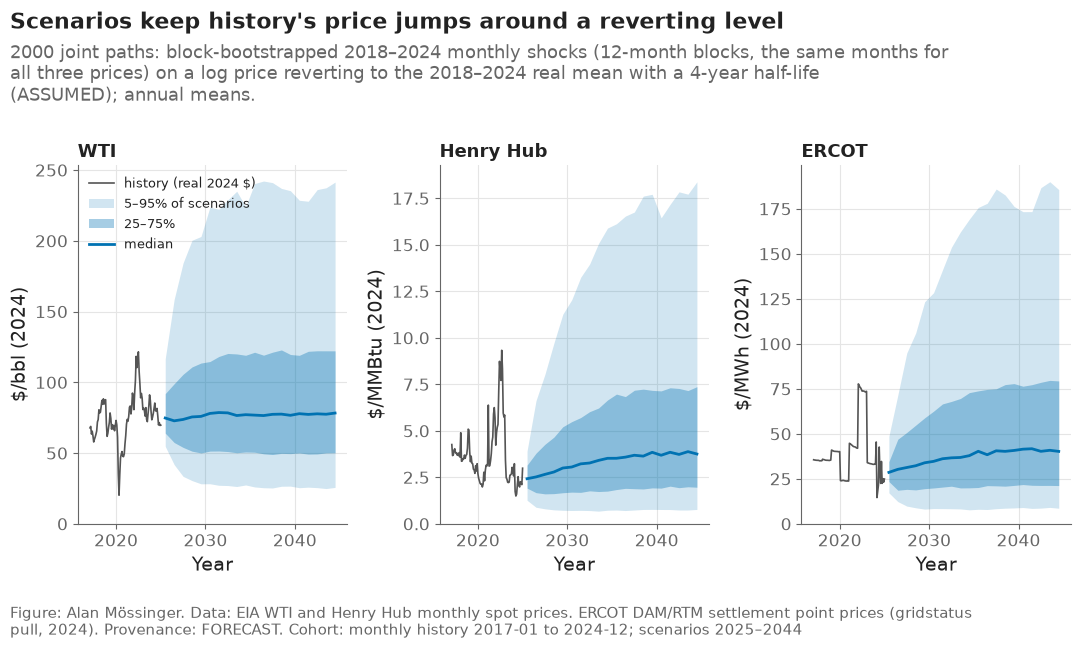

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(11, 6.5))
hist = market.set_index("month")
hist_cols = ["wti_usd_bbl_real2024", "hh_usd_mmbtu_real2024", "ercot_usd_mwh_real2024"]
units = ["$/bbl (2024)", "$/MMBtu (2024)", "$/MWh (2024)"]
for ax, name, col, unit in zip(axes, names, hist_cols, units):
    b = bands[bands["series"] == name]
    ax.plot(hist.index.year + hist.index.month / 12, hist[col], color="#555555", lw=1.2, label="history (real 2024 $)")
    ax.fill_between(b["year"] + 0.5, b["q05"], b["q95"], color="#0072B2", alpha=0.18, label="5–95% of scenarios")
    ax.fill_between(b["year"] + 0.5, b["q25"], b["q75"], color="#0072B2", alpha=0.35, label="25–75%")
    ax.plot(b["year"] + 0.5, b["q50"], color="#0072B2", lw=2, label="median")
    ax.set_title(name, fontsize=13)
    ax.set_ylabel(unit)
    ax.set_xlabel("Year")
    ax.set_ylim(0, None)
axes[0].legend(loc="upper left", fontsize=9)
wti_b = bands[(bands["series"] == "WTI") & (bands["year"] == 2034)].iloc[0]
plots.finish(fig,
             f"Ten years out the scenarios put WTI between \${wti_b['q05']:.0f} and \${wti_b['q95']:.0f} a barrel (5–95%): the history's own jumps around a level that reverts to the 2018–2024 mean",
             f"{N_SCEN} joint paths: block-bootstrapped 2018–2024 monthly shocks ({BLOCK}-month blocks, the same months for all three prices) on a log price reverting to the 2018–2024 real mean with a {HALF_LIFE // 12}-year half-life (ASSUMED); annual means.",
             "monthly history 2017-01 to 2024-12; scenarios 2025–2044", lbnl=False, sources=[config.SOURCE_EIA_PRICES, config.SOURCE_ERCOT], provenance="FORECAST")
plots.save_fig(fig, "F30_price_scenarios", "Fan of the joint price scenarios against the real-dollar history for WTI, Henry Hub and ERCOT.", NOTEBOOK)
plt.show()


**Reading this.** The fans widen for a few years and then settle, because the price reverts toward its 2018–2024 real mean with a four-year half-life; the long-run spread is the history's shock size divided by the reversion, about a factor of two either way for WTI. The half-life is an assumption and is in `scenario_settings.csv` beside the observed levels; the ERCOT fan inherits the assumed 2020–2023 months. A block of twelve months keeps a year of 2020 or 2022 intact, so the set contains collapses and spikes of the shape the market has produced, which a fitted normal would not.

## 2. Output, cost and timing draws

Output multipliers come from the scored holdout forecasts, one ratio per lease or plant: its actual output summed over its scored holdout months over the forecast summed over the same months (leases: the post-hoc level model labelled in notebook 05; plants: the registered challengers), bounded to [0.2, 3]; one draw per candidate per scenario, the lease draw weighted by the lease's forecast volume (a multiplier for a deepwater candidate comes from large producers' errors, not from the tail of small leases), the deviation from 1 widened by 1/completeness. A month-level ratio would mix shut-in months with producing ones and say nothing about a year. Costs move together by a triangular multiplier on the workover and operating cost (0.75–1.5, mode 1, ASSUMED). Operation years for the twenty requests come from the entry curves through the book simulation's copula with ρ = 0.041 (a draw of 0 is a request that never operates within seven years).

In [4]:
lease_ratios, lease_weights = sc.key_level_ratios(forecasts, "lease_oil_h3", pred_column="pred_level_posthoc", return_weights=True)  # one ratio per lease, weighted by its volume
cf_ratios = {t: sc.key_level_ratios(forecasts, f"cf_{t}_h1", pred_column="pred") for t in ("Solar", "Wind", "Gas CC")}  # one per plant
out_lease = sc.draw_multipliers(lease_ratios, N_SCEN, len(leases), seed=SEED + 10, weights=lease_weights)
out_lease = 1 + (out_lease - 1) / leases["data_completeness"].to_numpy()[None, :]
out_power = np.ones((N_SCEN, len(power)))
for j, r in power.iterrows():
    key = {"Solar": "Solar", "Wind": "Wind", "Gas CC": "Gas CC"}.get(r["technology"])
    if key:
        out_power[:, j] = sc.draw_multipliers(cf_ratios[key], N_SCEN, 1, seed=SEED + 20 + j)[:, 0]
cost_mult = sc.cost_multipliers(N_SCEN, seed=SEED + 30)
lm0 = pred_landmark[pred_landmark["landmark"].astype(str) == "0"].pivot(index="project_key", columns="horizon_after", values="entry model")
v2 = pred_v2[pred_v2["horizon"].isin([5, 7])].pivot(index="project_key", columns="horizon", values="chosen")
P = np.array([ec.operation_curve(k.split("|", 1)[1], lm0, v2, years=HORIZON_YEARS) for k in power["project_id"]])
op_year = portfolio.simulate_operation_years(P, power["technology"].to_numpy(), rho, n_draws=N_SCEN, seed=SEED + 40)
draw_summary = pd.DataFrame([
    {"draw": "lease output multiplier (per lease, scored months summed, volume-weighted draw)", "n_source_rows": len(lease_ratios), "mean": out_lease.mean(), "sd": out_lease.std(), "provenance": "FORECAST residuals (post-hoc level model), widened by 1/completeness"},
    {"draw": "solar/wind CF multiplier (per plant)", "n_source_rows": sum(len(v) for v in cf_ratios.values()), "mean": out_power[:, power['technology'].isin(['Solar', 'Wind']).to_numpy()].mean(), "sd": out_power[:, power['technology'].isin(['Solar', 'Wind']).to_numpy()].std(), "provenance": "FORECAST residuals"},
    {"draw": "cost multiplier", "n_source_rows": 0, "mean": cost_mult.mean(), "sd": cost_mult.std(), "provenance": "ASSUMED triangular 0.75–1.5"},
    {"draw": "share of requests never operating within 7 y", "n_source_rows": len(power), "mean": float((op_year == 0).mean()), "sd": np.nan, "provenance": "FORECAST (queue models) through the ρ copula"},
])
draw_summary.to_csv(R / "scenario_draws.csv", index=False)
print(f"timing: mean P(operation by 7 y) {P[:, -1].mean():.2f}; simulated share never operating {(op_year == 0).mean():.2f}; {time.time() - START:.0f} s")
draw_summary.round(3)


timing: mean P(operation by 7 y) 0.13; simulated share never operating 0.87; 2 s


,draw,n_source_rows,mean,sd,provenance
0,"lease output multiplier (per lease, scored mon...",1040,0.995,0.263,"FORECAST residuals (post-hoc level model), wid..."
1,solar/wind CF multiplier (per plant),415,0.980,0.235,FORECAST residuals
2,cost multiplier,0,1.084,0.161,ASSUMED triangular 0.75–1.5
3,share of requests never operating within 7 y,20,0.871,NaN,FORECAST (queue models) through the ρ copula


## 3. Every candidate under every scenario

Leases: the Arps baseline times the output multiplier, the scenario's WTI and Henry Hub paths, the cost multiplier on workover and operating cost, incremental NPV against doing nothing. Requests: the NPV if built, with its revenue scaled by the scenario's mean real ERCOT price over the plant's life relative to the 2024 base and by the capacity-factor multiplier, its fuel by the Henry Hub ratio, discounted from the drawn operation year; minus the cost to carry; −cost to carry when the request never operates. Both generators, merchant and contracted.

In [5]:
oil_w = lease.pivot(index="lease_number", columns="month", values="oil_bbl").fillna(0)
gas_w = lease.pivot(index="lease_number", columns="month", values="gas_mcf").fillna(0)
baselines = {}
for _, r in leases.iterrows():
    lid = r["project_id"].split("|")[1]
    bo, bg, _, _ = ec.lease_baseline(oil_w.loc[lid].to_numpy(), gas_w.loc[lid].to_numpy(), months=HORIZON)
    baselines[lid] = (bo, bg, int(r["n_wells"]))
g_base = ec.grid_case("base")


def lease_npvs(prices, out_mult, cost_mult_):
    """Incremental NPV of every lease in every scenario (prices: scenarios × months × 3)."""
    out = np.empty((prices.shape[0], len(leases)))
    for j, r in leases.iterrows():
        bo, bg, wells = baselines[r["project_id"].split("|")[1]]
        for s in range(prices.shape[0]):
            override = {"workover_cost_per_well_usd": g_base["workover_cost_per_well_usd"] * cost_mult_[s], "opex_usd_per_boe": g_base["opex_usd_per_boe"] * cost_mult_[s]}
            out[s, j] = ec.incremental_npv(bo * out_mult[s, j], bg * out_mult[s, j], prices[s, :, 0], prices[s, :, 1], wells, "base", override)
    return out


gas_mc = atb.loc["Gas", "heat_rate_mmbtu_per_mwh"] * BASE[1] + atb.loc["Gas", "vom_per_mwh"]
cap24 = ec.capture_factors(hub, wind_solar["solar_mw"], wind_solar["wind_mw"], gas_marginal_cost=gas_mc)  # the same 2024 basis as notebook 07
battery_rev = ec.battery_annual_revenue(hub, hours=4, efficiency=0.85, cycles=1.0)


def pv_components(tech):
    """Present values per MW at the operation date on the 2024 basis: merchant revenue, the fixed PPA years, the merchant tail, fixed costs, fuel."""
    a = atb.loc[tech]
    r = a["wacc_real"]
    disc = (1 + r) ** np.arange(1, LIFE + 1)
    if tech == "Battery":
        rev, mwh = battery_rev, 0.0
    else:
        cf = cap24["gas_hours_share"] if tech == "Gas" else a["new_build_cf"]
        mwh = cf * 8760
        rev = BASE[2] * {"Gas": cap24["gas"], "Solar": cap24["solar"], "Wind": cap24["wind"]}[tech] * mwh
    pv_rev = (rev / disc).sum()
    ppa_years = np.arange(1, LIFE + 1) <= 15
    pv_ppa_fixed = (np.where(ppa_years, PPA[tech] * mwh, 0.0) / disc).sum() if tech in PPA else 0.0
    pv_tail = (np.where(ppa_years, 0.0, rev) / disc).sum() if tech in PPA else pv_rev
    fuel = a["heat_rate_mmbtu_per_mwh"] * BASE[1] * mwh if tech == "Gas" else 0.0
    pv_fuel = (fuel / disc).sum()
    pv_fixed = a["capex_per_kw"] * 1000 + ((a["fom_per_kw_year"] * 1000 + a["vom_per_mwh"] * mwh) / disc).sum()
    return {"pv_rev": pv_rev, "pv_ppa_fixed": pv_ppa_fixed, "pv_tail": pv_tail, "pv_fuel": pv_fuel, "pv_fixed": pv_fixed, "rate": r, "cf_scales": tech in ("Solar", "Wind")}


tech_of = {"Gas CC": "Gas", "Solar": "Solar", "Wind": "Wind", "Storage": "Battery"}
components = {t: pv_components(tech_of[t]) for t in power["technology"].unique()}


def power_npvs(prices, out_mult, op_year_, case="merchant"):
    """NPV of every request in every scenario from the drawn operation year and the scenario's price ratios."""
    out = np.empty((prices.shape[0], len(power)))
    for j, r in power.iterrows():
        c = components[r["technology"]]
        years_j = op_year_[:, j]
        for s in range(prices.shape[0]):
            y = int(years_j[s])
            if y == 0:
                out[s, j] = -r["carry_cost"]
                continue
            window = slice((y - 1) * 12, min(HORIZON, (y - 1 + LIFE) * 12))
            ercot_ratio = prices[s, window, 2].mean() / BASE[2]
            hh_ratio = prices[s, window, 1].mean() / BASE[1]
            cf = out_mult[s, j] if c["cf_scales"] else 1.0
            if case == "contracted" and r["technology"] in ("Solar", "Wind"):
                pv_rev = (c["pv_ppa_fixed"] + c["pv_tail"] * ercot_ratio) * cf  # the PPA years are fixed in price, the tail is merchant
            else:
                pv_rev = c["pv_rev"] * ercot_ratio * cf
            npv_built = pv_rev - c["pv_fuel"] * hh_ratio - c["pv_fixed"]
            out[s, j] = npv_built * r["mw"] / (1 + c["rate"]) ** y - r["carry_cost"]
    return out


t0 = time.time()
npv_sets = {}
for gen_name, prices in (("primary", prices_primary), ("copula", prices_copula)):
    L = lease_npvs(prices, out_lease, cost_mult)
    for case in ("merchant", "contracted"):
        Pw = power_npvs(prices, out_power, op_year, case)
        npv_sets[(gen_name, case)] = np.concatenate([L, Pw], axis=1)
ids = list(leases["project_id"]) + list(power["project_id"])
long = pd.concat([pd.DataFrame(arr, columns=ids).assign(scenario=np.arange(N_SCEN), generator=g, revenue_case=c)
                  for (g, c), arr in npv_sets.items()], ignore_index=True)
long.to_parquet(paths.DATA_PROCESSED / "candidate_npv_scenarios.parquet", index=False)
print(f"{len(npv_sets)} scenario sets × {N_SCEN} scenarios × {len(ids)} candidates in {time.time() - t0:.0f} s")


4 scenario sets × 2000 scenarios × 40 candidates in 28 s


## 4. Risk per candidate and per book

P(NPV < 0), the 5% value at risk and the expected shortfall below it (CVaR 95%), for every candidate and for the default book, under the primary generator in both revenue cases, with the copula set beside it.

In [6]:
rows = []
for (g, c), arr in npv_sets.items():
    for j, pid in enumerate(ids):
        rows.append({"generator": g, "revenue_case": c, "project_id": pid, "sector": book.set_index("project_id").loc[pid, "sector"],
                     "technology": book.set_index("project_id").loc[pid, "technology"], **sc.risk_measures(arr[:, j], LEVEL)})
    rows.append({"generator": g, "revenue_case": c, "project_id": "BOOK (default 40)", "sector": "book", "technology": "", **sc.risk_measures(arr.sum(axis=1), LEVEL)})
    rows.append({"generator": g, "revenue_case": c, "project_id": "BOOK leases only", "sector": "book", "technology": "", **sc.risk_measures(arr[:, : len(leases)].sum(axis=1), LEVEL)})
    rows.append({"generator": g, "revenue_case": c, "project_id": "BOOK power only", "sector": "book", "technology": "", **sc.risk_measures(arr[:, len(leases):].sum(axis=1), LEVEL)})
summary = pd.DataFrame(rows)
summary.to_csv(R / "scenario_summary.csv", index=False)
bk = summary[(summary["generator"] == "primary") & (summary["project_id"] == "BOOK (default 40)")].set_index("revenue_case")
print(f"default book, primary scenarios: merchant mean ${bk.loc['merchant', 'mean'] / 1e9:.2f}B, P(NPV<0) {pct(bk.loc['merchant', 'p_negative'])}, VaR95 ${bk.loc['merchant', 'var'] / 1e9:.2f}B, CVaR95 ${bk.loc['merchant', 'cvar'] / 1e9:.2f}B; "
      f"contracted mean ${bk.loc['contracted', 'mean'] / 1e9:.2f}B, CVaR95 ${bk.loc['contracted', 'cvar'] / 1e9:.2f}B")
summary[(summary["generator"] == "primary") & (summary["revenue_case"] == "merchant") & (summary["sector"] != "book")].sort_values("cvar")[["project_id", "technology", "mean", "p_negative", "var", "cvar"]].round(0).head(12)


default book, primary scenarios: merchant mean $20.59B, P(NPV<0) 3.5%, VaR95 $0.94B, CVaR95 $-1.47B; contracted mean $20.73B, CVaR95 $-0.91B


,project_id,technology,mean,p_negative,var,cvar
23,REQ|ERCOT|20INR0225,Gas CC,49066211.0,1.0,-192216345.0,-448506224.0
31,REQ|ERCOT|21INR0344,Solar,-6851723.0,1.0,-83356746.0,-446692045.0
22,REQ|ERCOT|20INR0224,Gas CC,38297611.0,1.0,-140794431.0,-439283655.0
25,REQ|ERCOT|20INR0252,Gas CC,47024207.0,1.0,-239401528.0,-383842495.0
21,REQ|ERCOT|20INR0223,Gas CC,49419771.0,1.0,-265135507.0,-379771601.0
32,REQ|ERCOT|21INR0401,Wind,5629620.0,1.0,-84938313.0,-373307628.0
24,REQ|ERCOT|20INR0231,Gas CC,55913066.0,1.0,-55613934.0,-368900074.0
36,REQ|ERCOT|21INR0467,Wind,11814986.0,1.0,-127926571.0,-318153237.0
38,REQ|ERCOT|21INR0482,Storage,-13162943.0,1.0,-221308613.0,-290020764.0
20,REQ|ERCOT|20INR0047,Wind,14671595.0,1.0,-95488461.0,-289908826.0


C:\Users\alanm\AppData\Local\Temp\ipykernel_47908\3987236268.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[0].boxplot(data_l, vert=False, showfliers=False, widths=0.6, medianprops={"color": plots.INK})
C:\Users\alanm\AppData\Local\Temp\ipykernel_47908\3987236268.py:12: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  bp = axes[1].boxplot(data_p, vert=False, showfliers=False, widths=0.6, patch_artist=True, medianprops={"color": plots.INK})


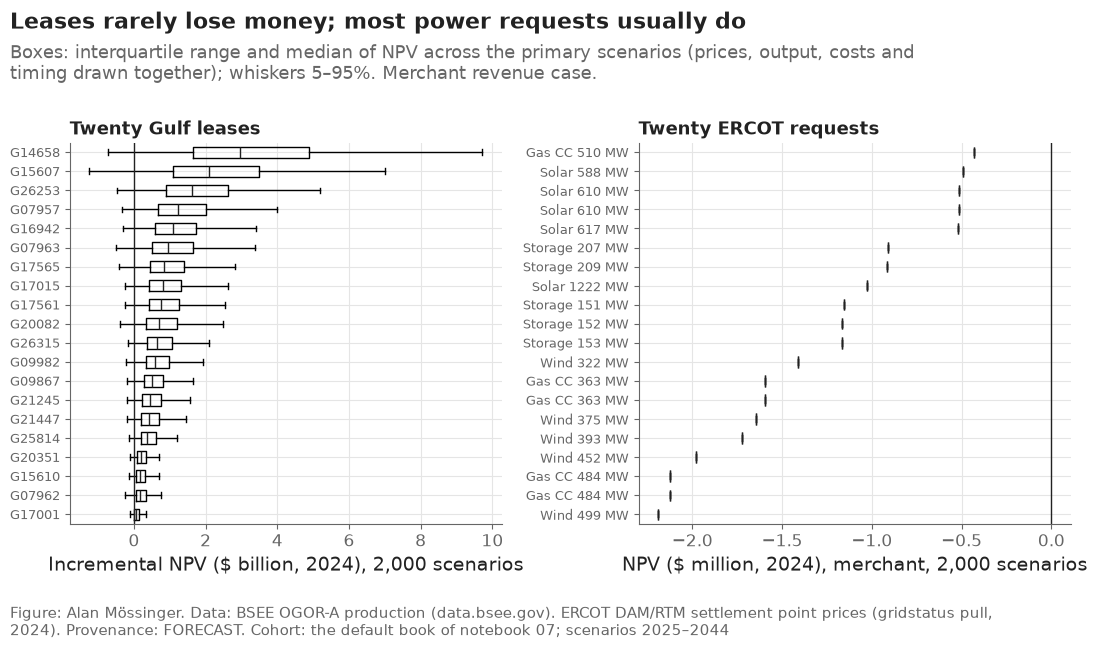

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 6.5), gridspec_kw={"width_ratios": [1, 1]})
arr = npv_sets[("primary", "merchant")]
order_l = np.argsort(np.median(arr[:, : len(leases)], axis=0))
data_l = [arr[:, j] / 1e9 for j in order_l]
axes[0].boxplot(data_l, vert=False, showfliers=False, widths=0.6, medianprops={"color": plots.INK})
axes[0].set_yticks(np.arange(1, len(leases) + 1), [leases.loc[j, "project_id"].split("|")[1] for j in order_l], fontsize=9)
axes[0].axvline(0, color=plots.INK, lw=1)
axes[0].set_xlabel("Incremental NPV ($ billion, 2024), 2,000 scenarios")
axes[0].set_title("Twenty Gulf leases", fontsize=13)
order_p = np.argsort(np.median(arr[:, len(leases):], axis=0))
data_p = [arr[:, len(leases) + j] / 1e6 for j in order_p]
bp = axes[1].boxplot(data_p, vert=False, showfliers=False, widths=0.6, patch_artist=True, medianprops={"color": plots.INK})
for patch, j in zip(bp["boxes"], order_p):
    patch.set_facecolor({"Gas CC": config.TECH_COLORS["Gas"], "Solar": config.TECH_COLORS["Solar"], "Wind": config.TECH_COLORS["Wind"], "Storage": config.TECH_COLORS["Battery"]}[power.loc[j, "technology"]])
    patch.set_alpha(0.7)
axes[1].set_yticks(np.arange(1, len(power) + 1), [f"{power.loc[j, 'technology']} {power.loc[j, 'mw']:.0f} MW" for j in order_p], fontsize=9)
axes[1].axvline(0, color=plots.INK, lw=1)
axes[1].set_xlabel("NPV ($ million, 2024), merchant, 2,000 scenarios")
axes[1].set_title("Twenty ERCOT requests", fontsize=13)
neg = summary[(summary["generator"] == "primary") & (summary["revenue_case"] == "merchant") & (summary["sector"] != "book")]
n_risky_leases = int((neg[neg["sector"] != "ERCOT power"]["p_negative"] > 0.05).sum())
n_neg_power = int((neg[neg["sector"] == "ERCOT power"]["p_negative"] > 0.5).sum())
cvar_b = bk.loc["merchant", "cvar"] / 1e9
title = (f"Under joint scenarios {n_risky_leases} of 20 leases lose money in more than one scenario in twenty and {n_neg_power} of 20 ERCOT requests lose in most; "
         + (f"the book's CVaR95 is \${cvar_b:.1f}B" if cvar_b >= 0 else f"the book's 5% shortfall averages \${-cvar_b:.1f}B below zero"))
plots.finish(fig, title,
             "Boxes: interquartile range and median of NPV across the primary scenarios (prices, output, costs and timing drawn together); whiskers 5–95%. Merchant revenue case.",
             "the default book of notebook 07; scenarios 2025–2044", lbnl=False, sources=[config.SOURCE_BSEE, config.SOURCE_ERCOT], provenance="FORECAST")
plots.save_fig(fig, "F31_candidate_risk", "NPV distributions of the forty candidates under the joint scenarios, merchant case.", NOTEBOOK)
plt.show()


**Reading this.** The leases carry wide boxes because oil moves and the uplift is an assumption, but their medians sit above zero; the requests carry narrow, negative boxes because at merchant prices on the 2024 basis the plant that is built does not earn its capital back, and the dominant draw is whether it is built at all — a request that never operates costs exactly its carry. That asymmetry is what the optimizer sees: the leases are the return, the contracted wind the diversifier, the rest of the power book a probability of a loss. The copula set in `scenario_summary.csv` tells the same story with thinner tails, which is the point of keeping it out of sample.

## 5. Named stresses

Deterministic what-ifs on the base case: WTI follows its 2020 path from the first month; Henry Hub +50%; a weak wind year (−15% capacity factor); solar curtailment (−10% revenue); a two-year delay for every request; and all of them at once with costs +20%. Each is a multiplier the report states, not a probability.

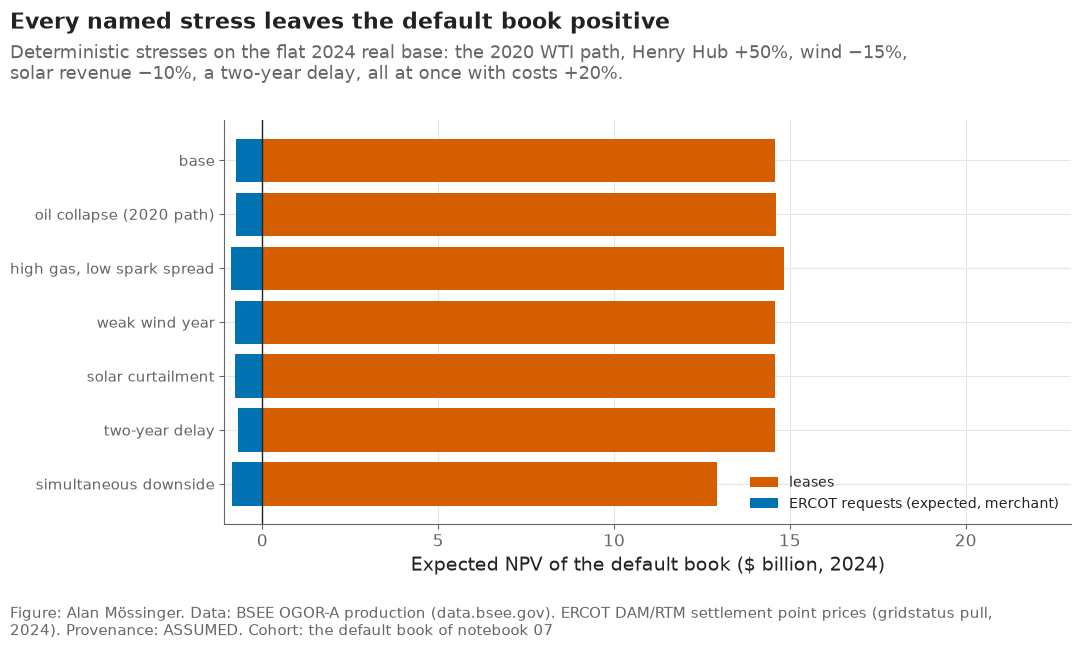

,stress,book_npv_leases,book_npv_power,book_npv,change_vs_base
0,base,1.458200e+10,-757000000.0,1.382500e+10,0.000000e+00
1,oil collapse (2020 path),1.460400e+10,-757000000.0,1.384700e+10,2.200000e+07
2,"high gas, low spark spread",1.483600e+10,-897000000.0,1.393900e+10,1.130000e+08
3,weak wind year,1.458200e+10,-788000000.0,1.379400e+10,-3.100000e+07
4,solar curtailment,1.458200e+10,-773000000.0,1.380900e+10,-1.600000e+07
5,two-year delay,1.458200e+10,-694000000.0,1.388800e+10,6.300000e+07
6,simultaneous downside,1.293300e+10,-863000000.0,1.206900e+10,-1.756000e+09


In [8]:
wti_2020 = market.set_index("month").loc["2019-12-01":"2021-12-01", "wti_usd_bbl_real2024"].to_numpy()
wti_2020 = wti_2020 * BASE[0] / wti_2020[0]  # the 2020 shape, started from the base level
flat = np.ones((1, HORIZON, 3)) * BASE[None, None, :]
stress_rows, stress_candidate_rows = [], []
for name, stress in sc.STRESSES.items():
    prices = sc.stress_prices(flat[0], stress, wti_2020_path=wti_2020)[None, :, :]
    cost = np.array([stress.get("cost", 1.0)])
    outl = np.ones((1, len(leases)))
    L = lease_npvs(prices, outl, cost)
    outp = np.ones((1, len(power)))
    if "wind_cf" in stress:
        outp[0, power["technology"].eq("Wind").to_numpy()] = stress["wind_cf"]
    if "solar_revenue" in stress:
        outp[0, power["technology"].eq("Solar").to_numpy()] = stress["solar_revenue"]
    # timing: expected value over the entry curve, shifted by the delay
    delay = stress.get("delay_years", 0)
    exp_power = np.zeros(len(power))
    for j, r in power.iterrows():
        curve = P[j]
        inc = np.diff(np.concatenate([[0.0], curve]))
        val = 0.0
        for y in range(1, HORIZON_YEARS + 1):
            oy = np.zeros((1, len(power)), int)  # one column per request; only column j is read
            oy[0, j] = y + delay
            val += inc[y - 1] * power_npvs(prices, outp, oy, "merchant")[0, j]
        exp_power[j] = val - (1 - curve[-1]) * r["carry_cost"]  # the share that never operates costs its carry
    stress_rows.append({"stress": name, "book_npv_leases": float(L.sum()), "book_npv_power": float(exp_power.sum()), "book_npv": float(L.sum() + exp_power.sum()), **{k: str(v) for k, v in stress.items()}})
    stress_candidate_rows += [{"stress": name, "project_id": pid, "npv": float(v)} for pid, v in zip(list(leases["project_id"]) + list(power["project_id"]), np.concatenate([L[0], exp_power]))]
stresses = pd.DataFrame(stress_rows)
stress_candidates = pd.DataFrame(stress_candidate_rows)
stress_candidates.to_csv(R / "stress_candidates.csv", index=False)
stresses["change_vs_base"] = stresses["book_npv"] - stresses.loc[0, "book_npv"]
stresses.to_csv(R / "stress_tests.csv", index=False)
fig, ax = plt.subplots(figsize=(11, 6.5))
y = np.arange(len(stresses))
ax.barh(y, stresses["book_npv_leases"] / 1e9, color="#D55E00", label="leases")
ax.barh(y, stresses["book_npv_power"] / 1e9, left=np.minimum(stresses["book_npv_leases"] / 1e9, 0), color="#0072B2", label="ERCOT requests (expected, merchant)")
ax.set_yticks(y, stresses["stress"], fontsize=10.5)
ax.invert_yaxis()
ax.axvline(0, color=plots.INK, lw=1)
ax.set_xlabel("Expected NPV of the default book ($ billion, 2024)")
ax.set_xlim(min(0, stresses["book_npv_power"].min() / 1e9 * 1.2), stresses["book_npv_leases"].max() / 1e9 * 1.55)
ax.legend(loc="lower right", fontsize=10)
worst = stresses.sort_values("book_npv").iloc[0]
plots.finish(fig,
             (f"The book keeps a positive expected NPV in every named stress; the worst, '{worst['stress']}', takes it to \${worst['book_npv'] / 1e9:.1f}B from \${stresses.loc[0, 'book_npv'] / 1e9:.1f}B"
              if worst["book_npv"] > 0 else f"The stress '{worst['stress']}' takes the book's expected NPV below zero, to \${worst['book_npv'] / 1e9:.1f}B from \${stresses.loc[0, 'book_npv'] / 1e9:.1f}B"),
             "Deterministic stresses on the flat 2024 real base: the 2020 WTI path, Henry Hub +50%, wind −15%, solar revenue −10%, a two-year delay, all at once with costs +20%.",
             "the default book of notebook 07", lbnl=False, sources=[config.SOURCE_BSEE, config.SOURCE_ERCOT], provenance="ASSUMED")
plots.save_fig(fig, "F32_stresses", "Expected NPV of the default book under each named stress, leases and requests separately.", NOTEBOOK)
plt.show()
stresses[["stress", "book_npv_leases", "book_npv_power", "book_npv", "change_vs_base"]].round(-6)


**Reading this.** The stresses are the questions a committee asks in words, answered in the same dollars as the scenarios. The oil path of 2020 is the one that matters for this book, because the leases are the book; the power-side stresses move the total by amounts the leases' own uncertainty dwarfs. That is a finding about the default book's balance, and it is the reason notebook 09 compares a risk-aware allocation with one that chases expected NPV alone.

## 6. What the correlations are worth

The same bootstrap with each series resampled on its own (correlations removed, marginals kept): the book's CVaR with and without the co-movement of oil, gas and power. A diversification benefit that only exists when the correlations are ignored is not a benefit.

In [9]:
indep = np.stack([sc.block_bootstrap_paths(changes[:, [k]], N_SCEN, HORIZON, block=BLOCK, seed=SEED + 100 + k)[:, :, 0] for k in range(3)], axis=2)
prices_indep = sc.mean_reverting_prices(indep, BASE, LONG_RUN, HALF_LIFE)
L_ind = lease_npvs(prices_indep, out_lease, cost_mult)
P_ind = power_npvs(prices_indep, out_power, op_year, "merchant")
indep_all = np.concatenate([L_ind, P_ind], axis=1)
P_ind_c = power_npvs(prices_indep, out_power, op_year, "contracted")
long_ind = pd.concat([pd.DataFrame(indep_all, columns=ids).assign(scenario=np.arange(N_SCEN), generator="independent", revenue_case="merchant"),
                      pd.DataFrame(np.concatenate([L_ind, P_ind_c], axis=1), columns=ids).assign(scenario=np.arange(N_SCEN), generator="independent", revenue_case="contracted")], ignore_index=True)
pd.concat([long, long_ind], ignore_index=True).to_parquet(paths.DATA_PROCESSED / "candidate_npv_scenarios.parquet", index=False)
joint_book = npv_sets[("primary", "merchant")].sum(axis=1)
indep_book = indep_all.sum(axis=1)
ablation = pd.DataFrame([{"scenarios": "joint (correlations kept)", **sc.risk_measures(joint_book, LEVEL)},
                         {"scenarios": "independent (correlations removed)", **sc.risk_measures(indep_book, LEVEL)}])
ablation["cvar_difference_vs_joint"] = ablation["cvar"] - ablation.loc[0, "cvar"]
ablation.to_csv(R / "correlation_ablation.csv", index=False)
print(f"book CVaR95 joint ${ablation.loc[0, 'cvar'] / 1e9:.2f}B vs independent ${ablation.loc[1, 'cvar'] / 1e9:.2f}B; "
      f"sd joint ${ablation.loc[0, 'sd'] / 1e9:.2f}B vs independent ${ablation.loc[1, 'sd'] / 1e9:.2f}B; {(time.time() - START) / 60:.1f} min")
ablation.round(-6)


book CVaR95 joint $-1.47B vs independent $0.34B; sd joint $16.72B vs independent $15.68B; 0.8 min


,scenarios,mean,sd,p_negative,var,cvar,cvar_difference_vs_joint
0,joint (correlations kept),2.059000e+10,1.671700e+10,0.0,9.420000e+08,-1.473000e+09,0.000000e+00
1,independent (correlations removed),2.067300e+10,1.567600e+10,0.0,2.543000e+09,3.380000e+08,1.811000e+09


**Reading this.** The difference between the two rows is the price of ignoring co-movement: when oil and gas are drawn independently the book's tail looks thinner than it is, because the scenarios in which both fall together are too rare. The number is small for this book because the leases dominate and they all move with oil; it would grow in a book balanced across sectors, which is the case notebook 09 builds.

## 7. Checks

In [10]:
checks = pd.DataFrame([
    ("scenario count and horizon as registered", bool(prices_primary.shape == (N_SCEN, HORIZON, 3) and prices_copula.shape == (N_SCEN, HORIZON, 3))),
    ("seed reproduces the primary set", bool(np.array_equal(primary, sc.block_bootstrap_paths(changes, N_SCEN, HORIZON, block=BLOCK, seed=SEED)))),
    ("correlations preserved within 0.1 by the primary generator", bool((corr_table[corr_table['generator'].str.startswith('primary')].eval('abs(historical - simulated)') < 0.1).all())),
    ("every candidate has an NPV in every scenario of every set", bool(all(np.isfinite(a).all() for a in npv_sets.values()))),
    ("a request that never operates costs its carry", bool(np.allclose(npv_sets[('primary', 'merchant')][:, len(leases):][op_year == 0], -np.broadcast_to(power['carry_cost'].to_numpy(), op_year.shape)[op_year == 0]))),
    ("stresses: base row equals the flat-price book", bool(abs(stresses.loc[0, 'book_npv_leases'] - lease_npvs(flat, np.ones((1, len(leases))), np.array([1.0])).sum()) < 1)),
    ("F30–F32 saved", all((paths.FIGURES / f).exists() for f in ("F30_price_scenarios.png", "F31_candidate_risk.png", "F32_stresses.png"))),
], columns=["check", "passed"])
checks["result"] = np.where(checks["passed"], "PASS", "FAIL")
checks.to_csv(R / "scenarios_checks.csv", index=False)
assert checks["passed"].all(), checks
print(f"run time {(time.time() - START) / 60:.1f} min")
checks[["check", "result"]]


run time 0.8 min


,check,result
0,scenario count and horizon as registered,PASS
1,seed reproduces the primary set,PASS
2,correlations preserved within 0.1 by the prima...,PASS
3,every candidate has an NPV in every scenario o...,PASS
4,a request that never operates costs its carry,PASS
5,stresses: base row equals the flat-price book,PASS
6,F30–F32 saved,PASS


## Takeaways

- 2,000 joint scenarios from the history's own monthly moves keep the cross-correlations and the 2020 and 2022 episodes; a copula set with thinner tails is held out for notebook 09.
- Output uncertainty comes from the scored forecast residuals of notebook 05 (widened where data are thin), costs from the grid, timing from the queue models through the ρ copula.
- Every candidate and the book carry P(NPV < 0), VaR and CVaR in both revenue cases; the named stresses are answered in the same dollars; the correlation ablation prices the co-movement.
- **What goes to the report:** F30–F32, `results/scenario_summary.csv`, `results/stress_tests.csv`, `results/correlation_ablation.csv`, `results/scenario_settings.csv`.